In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('placement.csv')

In [3]:
df.shape


(100, 4)

In [4]:
df.sample(5)

,Unnamed: 0,cgpa,iq,placement
72,72,7.3,116.0,1
68,68,4.0,75.0,0
91,91,7.5,158.0,1
12,12,5.4,139.0,0
87,87,5.7,132.0,1


C:\Users\Admin\AppData\Local\Temp\ipykernel_9700\49520821.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['cgpa'])


KeyError: 'placement_exam_marks'

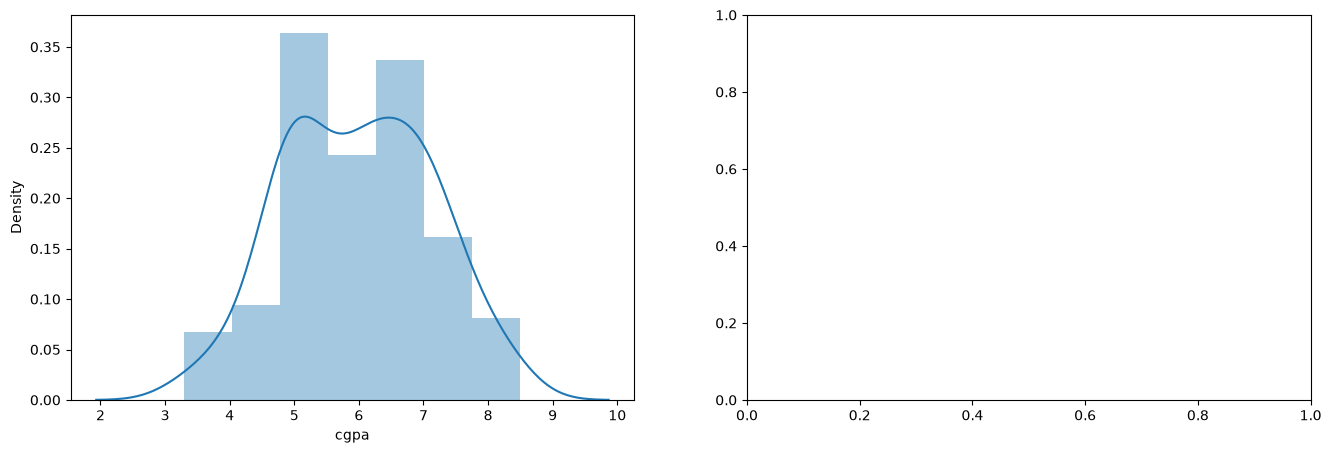

In [5]:
plt.figure(figsize=(16,5))
plt.subplot(1,2,1)
sns.distplot(df['cgpa'])

plt.subplot(1,2,2)
sns.distplot(df['placement_exam_marks'])

plt.show()


In [9]:
print(df.columns)

Index(['Unnamed: 0', 'cgpa', 'iq', 'placement'], dtype='object')


In [7]:
print("Mean value of cgpa",df['cgpa'].mean())
print("Std value of cgpa",df['cgpa'].std())
print("Min value of cgpa",df['cgpa'].min())
print("Max value of cgpa",df['cgpa'].max())

Mean value of cgpa 5.9910000000000005
Std value of cgpa 1.1436336737775692
Min value of cgpa 3.3
Max value of cgpa 8.5


In [10]:
# Finding the boundary values
print("Highest allowed",df['cgpa'].mean() + 3*df['cgpa'].std())
print("Lowest allowed",df['cgpa'].mean() - 3*df['cgpa'].std())

Highest allowed 9.421901021332708
Lowest allowed 2.560098978667293


In [11]:
# Trimming

new_df = df[(df['cgpa'] < 8.80) & (df['cgpa'] > 5.11)]
new_df

,Unnamed: 0,cgpa,iq,placement
0,0,6.8,123.0,1
1,1,5.9,106.0,0
2,2,5.3,121.0,0
3,3,7.4,132.0,1
4,4,5.8,142.0,0
...,...,...,...,...
92,92,5.2,110.0,0
93,93,6.8,112.0,1
97,97,6.7,182.0,1
98,98,6.3,103.0,1


In [12]:
# Approach 2

# Calculating the Zscore

df['cgpa_zscore'] = (df['cgpa'] - df['cgpa'].mean())/df['cgpa'].std()

In [13]:
df.head()

,Unnamed: 0,cgpa,iq,placement,cgpa_zscore
0,0,6.8,123.0,1,0.707394
1,1,5.9,106.0,0,-0.079571
2,2,5.3,121.0,0,-0.604214
3,3,7.4,132.0,1,1.232038
4,4,5.8,142.0,0,-0.167012


In [14]:
df[df['cgpa_zscore'] > 3]

,Unnamed: 0,cgpa,iq,placement,cgpa_zscore


In [15]:
df[df['cgpa_zscore'] < -3]

,Unnamed: 0,cgpa,iq,placement,cgpa_zscore


In [16]:
df[(df['cgpa_zscore'] > 3) | (df['cgpa_zscore'] < -3)]

,Unnamed: 0,cgpa,iq,placement,cgpa_zscore


In [17]:
new_df

,Unnamed: 0,cgpa,iq,placement
0,0,6.8,123.0,1
1,1,5.9,106.0,0
2,2,5.3,121.0,0
3,3,7.4,132.0,1
4,4,5.8,142.0,0
...,...,...,...,...
92,92,5.2,110.0,0
93,93,6.8,112.0,1
97,97,6.7,182.0,1
98,98,6.3,103.0,1


In [18]:
upper_limit = df['cgpa'].mean() + 3*df['cgpa'].std()
lower_limit = df['cgpa'].mean() - 3*df['cgpa'].std()